# Measuring how someone walks from a video

*This project is a prototype and is not medical advice.*

**The idea in one paragraph.** After an injury or an operation, a physiotherapist wants to know whether a patient's walking is getting better. Hospitals measure this in a gait lab. Cameras track markers on the body and pressure plates record toe-off and heel strike events. Most clinics do not have a lab. We built a tool that computes the same quantities from a phone video filmed from the side, and we checked it against gait lab measurements of people the tool had never seen.

**How to read this notebook.** Each section asks a question, shows a figure, and ends with the answer
to the question. No background in biomechanics is necessary. The words you need are below.

| Word | Meaning |
|---|---|
| **Stride** | One full walking cycle: from one foot touching the ground to the same foot touching it again (about 1 second). |
| **Heel strike / toe-off** | The moment a foot lands / leaves the ground. Everything about timing is measured between these moments. |
| **Stance / swing** | The part of a stride the foot is on the ground (~60 %) / in the air (~40 %). |
| **Step time** | Time from one foot landing to the *other* foot landing. |
| **Cadence** | Steps per minute. |
| **Range of motion (ROM)** | How far a joint (hip, knee, ankle) bends during a stride, in degrees: most bent minus least bent. |
| **Symmetry index (SI)** | How different left and right are, in %. 0 = identical; +10 = the left value is 10 % larger. |
| **Motion capture (mocap)** | The gait lab reference: millimetre level accuracy 3D marker tracking. What we treat as the "ground truth". |
| **Pose estimation** | Software that finds body points (hips, knees, ankles, heels, toes) in ordinary video. Less accurate with a lot of noise. |
| **Held-out people** | People whose data was never used to build the model, so the test is fair. |

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from helpers.analysis import ROOT, SERIES, SIDE_COL, INK2, MUTED, SURFACE, style, all_trials, load_npz, cycle_curves
from helpers import gaitdata as G
style()
pd.set_option("display.precision", 2)
EVAL, KUO = ROOT / "outputs" / "eval", ROOT / "outputs" / "kuopio"
MODEL, CLASSIC, GUESS = SERIES[0], MUTED, "#c3c2b7"      # one colour per method, used throughout

## 1. Converting walking into time-variant 2D coordinates

Below is 5 seconds of a real person walking on a treadmill, recorded in a gait lab. The top chart shows when each foot is on the ground (a bar) and in the air (a gap). The bottom chart shows how much the left knee is bent. Every number this tool reports comes from when the feet land and lift, and how much the joints bend.

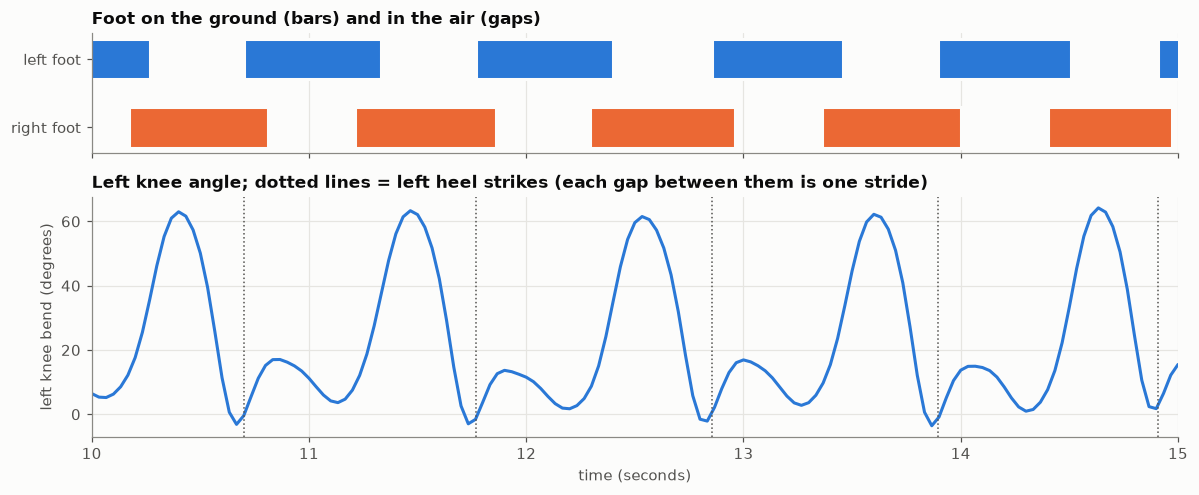

This person: 114 steps per minute, one stride every 1.05 s, foot on the ground 60 % of each stride.


In [2]:
test = G.load_all()["test"]
tr = next(t for t in test if t.ds == "fukuchi" and t.mode == "treadmill" and t.trial.endswith("T05"))
t0, t1 = 10.0, 15.0
fig, (a, b) = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
for k, s in enumerate("LR"):
    hs, to = tr.events[f"HS_{s}"], tr.events[f"TO_{s}"]
    for h in hs:
        nxt = to[to > h]
        if len(nxt) and t0 - 1 < h < t1:
            a.barh(1 - k, nxt[0] - h, left=h, height=0.6, color=SIDE_COL[s], edgecolor=SURFACE, linewidth=2)
a.set_yticks([1, 0], ["left foot", "right foot"]); a.grid(axis="y", visible=False)
a.set_title("Foot on the ground (bars) and in the air (gaps)")
t = np.arange(len(tr.ang)) / G.FS
ok = (t >= t0) & (t <= t1)
b.plot(t[ok], tr.ang[ok, G.ANG_NAMES.index("L_knee")], color=SIDE_COL["L"])
for h in tr.events["HS_L"]:
    if t0 <= h <= t1:
        b.axvline(h, color=INK2, lw=1, ls=":")
b.set_ylabel("left knee bend (degrees)"); b.set_xlabel("time (seconds)")
b.set_title("Left knee angle; dotted lines = left heel strikes (each gap between them is one stride)")
b.set_xlim(t0, t1)
fig.tight_layout(); plt.show()
S = tr.strides
print(f"This person: {120 / S[:, 3].mean():.0f} steps per minute, one stride every {S[:, 3].mean():.2f} s, "
      f"foot on the ground {S[:, 7].mean():.0f} % of each stride.")

Walking is a very regular rhythm. Landing and lift-off times give the timing numbers (cadence, stride, stance, swing). the joint angles give us the range of motion(ROM).

## 2. What is a normal stride?

Here are the hip, knee and ankle angles through one stride, averaged over many healthy adults (the band
shows how much it varies). The stride starts and ends when the heel lands. The range of motion is the
height difference between the lowest and highest point on the curve. A stiff knee after surgery shows up as a flatter knee curve for example.

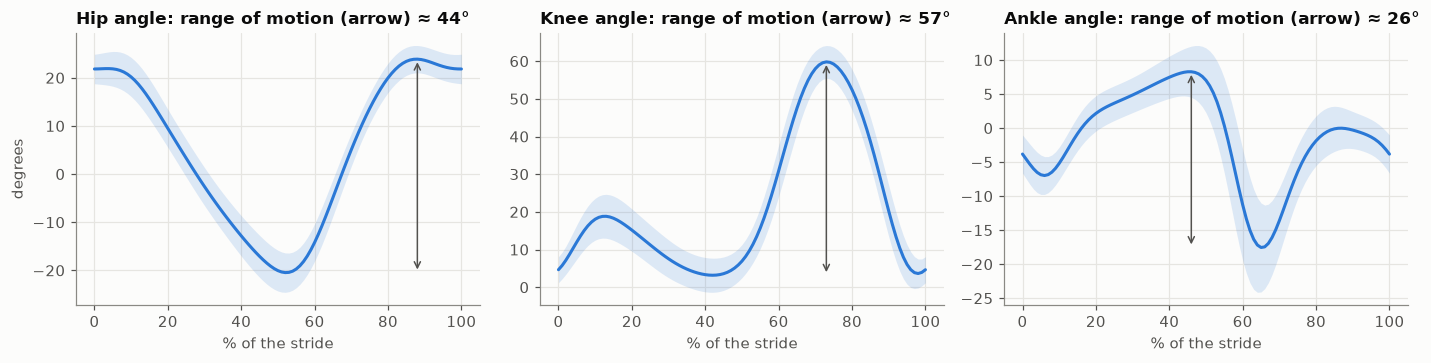

In [3]:
T = all_trials()
pick = T[(T.dataset == "fukuchi") & (T["mode"] == "treadmill") & T.speed_label.isin(["T04", "T05", "T06"])].trial
curves = {j: [] for j in ("hip", "knee", "ankle")}
for trial in pick.sample(40, random_state=0):
    c = cycle_curves(load_npz("fukuchi", trial))
    for j in curves:
        curves[j] += [c[f"{s}_{j}"].mean(0) for s in "LR" if len(c[f"{s}_{j}"])]
x = np.linspace(0, 100, 101)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for a, (j, cs) in zip(axs, curves.items()):
    cs = np.array(cs); m, sd = cs.mean(0), cs.std(0)
    a.fill_between(x, m - sd, m + sd, color=SERIES[0], alpha=0.15, lw=0)
    a.plot(x, m, color=SERIES[0])
    a.annotate("", xy=(x[m.argmax()], m.max()), xytext=(x[m.argmax()], m.min()),
               arrowprops=dict(arrowstyle="<->", color=INK2, lw=1))
    a.set_title(f"{j.capitalize()} angle: range of motion (arrow) ≈ {np.ptp(m):.0f}°"); a.set_xlabel("% of the stride")
axs[0].set_ylabel("degrees")
fig.tight_layout(); plt.show()

Healthy walking follows the same shape every stride and in every person, so changes such as a knee that
bends 10° less than it should are measurable.

## 3. The importance of symmetry, and spotting it
After an injury, people often favour one leg. They usually land on it for a shorter time or bend it less. The symmetry index compares left and right in percentages. The chart shows the step-time symmetry of every recording in our datasets (thousands of people walking normally). Almost everyone is within a few percent of perfect symmetry. A difference of 5–10% between two steps is on the scale of tens of
milliseconds. This makes it virtually impossible to eyeball, but it's what a physiotherapist wants to track.

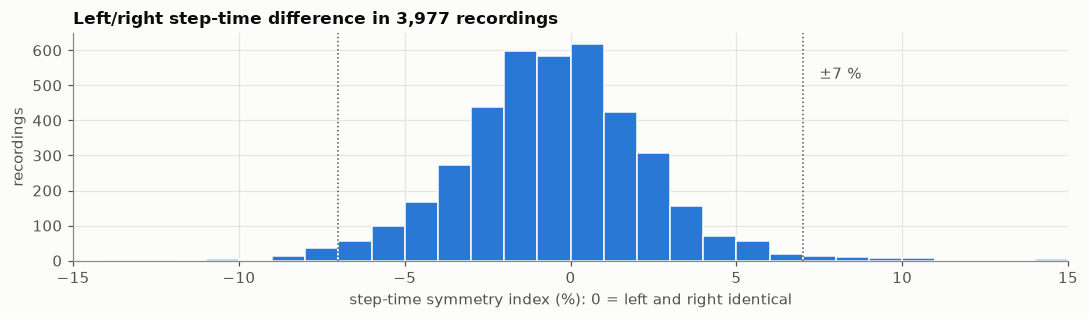

75% of recordings are within ±3 %; 3% differ by 7 % or more.


In [4]:
si = T.SI_step_time.dropna()
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(si.clip(-15, 15), bins=np.arange(-15, 15.5, 1), color=SERIES[0], edgecolor=SURFACE, linewidth=1)
ax.set_xlim(-15, 15)
for v in (-7, 7):
    ax.axvline(v, color=INK2, ls=":", lw=1)
ax.text(7.5, ax.get_ylim()[1] * 0.8, "±7 %", color=INK2)
ax.set_xlabel("step-time symmetry index (%): 0 = left and right identical")
ax.set_ylabel("recordings"); ax.set_title(f"Left/right step-time difference in {len(si):,} recordings")
fig.tight_layout(); plt.show()
print(f"{(si.abs() < 3).mean():.0%} of recordings are within ±3 %; {(si.abs() >= 7).mean():.0%} differ by 7 % or more.")

Most people are nearly symmetric, so the useful signal is a small difference. A tool is only helpful if it reports such differences at their true size. (section 7 focuses on this)

## 4. The data, and what a video actually "sees"

We used four public research datasets. All of them are gait-lab recordings, so we always know the right
answer. For every person we split the data so that the people we test on were never used for training.

| Dataset | Who | People | Used for |
|---|---|---|---|
| Fukuchi | healthy young and older adults, treadmill and floor | 51 | training and testing |
| Ferber | patients of a running-injury clinic, walking on a treadmill | 1,670 | training and testing |
| Toronto | older adults (average age ~80) | 11 | testing only |
| Kuopio | adults filmed by a **real video camera** at the same time as the gait lab | 42 | the final real-video test |

The picture shows one moment from the Kuopio data: the dots and lines are where the pose-estimation software
thinks the joints are in the video, and the grey skeleton is where the gait lab measured them. They are close
but not identical, and the leg further from the camera is harder to see. Trying to account for that mismatch is the
main job of our model.

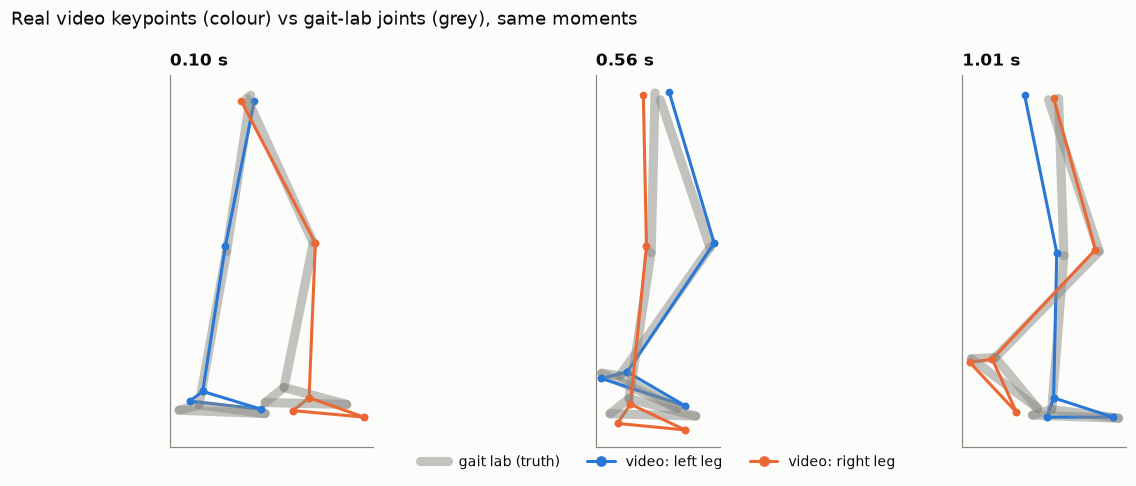

In [5]:
import pickle
clips = pickle.load(open(ROOT / "data" / "processed" / "kuopio_clips.pkl", "rb"))
meta = pd.read_csv(KUO / "clips.csv", dtype={"subject": str}).query("swap_frac == 0").sort_values("sync_err_px").iloc[0]
c = next(k for k in clips if k["subject"] == meta.subject and k["trial"] == meta.trial)
J = {n: i for i, n in enumerate(["L_hip", "L_knee", "L_ankle", "L_heel", "L_toe", "R_hip", "R_knee", "R_ankle", "R_heel", "R_toe", "pelvis"])}
bones = [("hip", "knee"), ("knee", "ankle"), ("ankle", "heel"), ("heel", "toe"), ("ankle", "toe")]
frames = np.linspace(10, len(c["px"]) - 10, 3).astype(int)
fig, axs = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for a, f in zip(axs, frames):
    for s in "LR":
        for p, q in bones:  # noqa
            i, k = J[f"{s}_{p}"], J[f"{s}_{q}"]
            a.plot(*c["truth_px"][f, [i, k]].T, color=MUTED, lw=6, alpha=0.5, solid_capstyle="round")
            a.plot(*c["px"][f, [i, k]].T, color=SIDE_COL[s], lw=2, marker="o", ms=4)
    a.set_aspect("equal"); a.invert_yaxis() if a is axs[0] else None
    a.set_title(f"{f / c['fps']:.2f} s"); a.set_xticks([]); a.set_yticks([])
axs[0].plot([], [], color=MUTED, lw=6, alpha=0.5, label="gait lab (truth)")
axs[0].plot([], [], color=SIDE_COL["L"], marker="o", label="video: left leg")
axs[0].plot([], [], color=SIDE_COL["R"], marker="o", label="video: right leg")
fig.legend(loc="lower center", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Real video keypoints (colour) vs gait-lab joints (grey), same moments", x=0.01, ha="left")
fig.tight_layout(); plt.show()

Video keypoints are noticeably less precise than the gait lab.(especially at the feet) That is why we don't just measure angles off the video. We need a more robust model.

## 5. How the model works, in plain words

1. **Find the body in the video.** Pose-estimation models marks the hips, knees, ankles,
   heels and toes in every frame. We fix frames where it mixes up the left and right leg, and rescale the body to a standard size so that camera distance and body height do not matter.
2. **Run inference on the walking pattern.** A neural network (a *bidirectional GRU*, a model built for sequences) looks
   at 5 seconds of these points at once, forwards and backwards in time. For every frame it outputs
   (a) how likely it is that a heel is landing or a toe is leaving the ground, and (b) a cleaned-up estimate
   of the hip, knee and ankle angles.
3. **Measure quantities.** From landing times and angles we compute every number (cadence, stance
   time, range of motion, symmetry) with the same formulas a gait lab uses. The model predicts only the inputs to these formulas. So the outputs mean exactly what the gait-lab numbers mean.

**Learning without real video.** Gait labs record perfect marker positions, which don't reflect phone video quality much. So in
training we augmented the gait lab data to look like video: shakyness, points that disappear, a far leg that hides behind the near one, slightly tilted camera angles, etc. We also invented lopsided walkers
(one leg shifted or stiffened) so the model learns that the two legs can differ. Below is the model at work
on a held-out person, with video-like damage added.

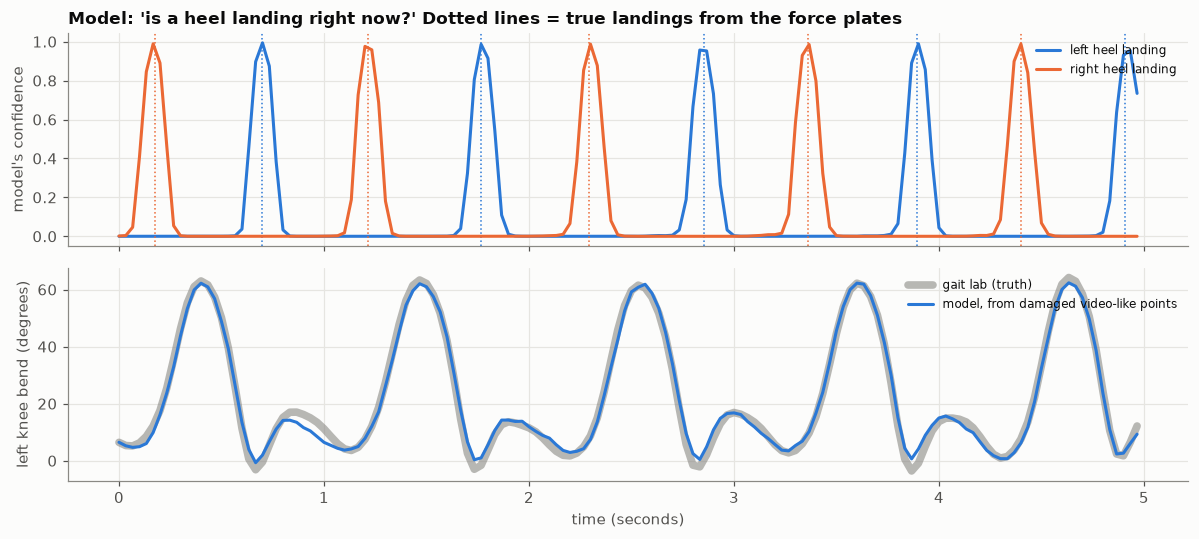

Left heel landings found: 5; average timing error 6 ms (one video frame is 33 ms).


In [6]:
import augment
from evaluate import load_model, run_model
from model import decode_events
x, v = augment.apply(tr.pose[300:450], np.random.default_rng(3), augment.Noise.level(0.02))
m, cfg, norm = load_model()
probs, _, ang = run_model(m, norm, [x], [v])
t = np.arange(150) / G.FS
fig, (a, b) = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for s in "LR":
    a.plot(t, probs[0][:, G.EVENTS.index(f"HS_{s}")], color=SIDE_COL[s], label=f"{'left' if s == 'L' else 'right'} heel landing")
    for e in tr.events[f"HS_{s}"] - 10:
        if 0 <= e <= 5:
            a.axvline(e, color=SIDE_COL[s], lw=1, ls=":")
a.set_ylabel("model's confidence"); a.legend(fontsize=8, loc="upper right")
a.set_title("Model: 'is a heel landing right now?' Dotted lines = true landings from the force plates")
i = G.ANG_NAMES.index("L_knee")
b.plot(t, tr.ang[300:450, i], color=MUTED, lw=5, alpha=0.6, label="gait lab (truth)")
b.plot(t, ang[0][:, i], color=MODEL, label="model, from damaged video-like points")
b.set_ylabel("left knee bend (degrees)"); b.set_xlabel("time (seconds)"); b.legend(fontsize=8, loc="upper right")
fig.tight_layout(); plt.show()
pred = decode_events(probs[0])["HS_L"]
true = tr.events["HS_L"] - 10
err = [1000 * min(abs(p - true)) for p in pred]
print(f"Left heel landings found: {len(pred)}; average timing error {np.mean(err):.0f} ms (one video frame is 33 ms).")

## 6. Robustness of the model on unseen data

We tested on the held-out people with the same video-like damage, and compared three approaches:

* **Our model**.
* **The classic method**: the textbook way, measuring straight off the points with smoothing and fixed rules,
  with no learning. This is what physio software without machine learning ships with.
* **Guessing the average**: always answering with the typical value. Any useful tool must beat this.

Each chart shows the *average error* (smaller is better) on the largest test group (Ferber, 251 people).

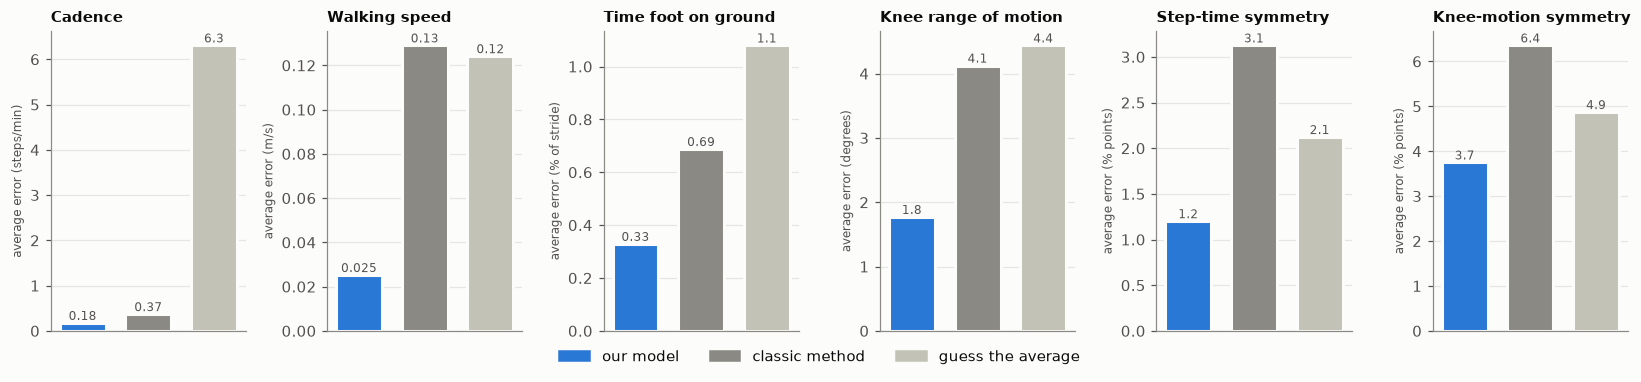

In [7]:
R = pd.read_csv(EVAL / "test" / "regression.csv")
R = R[(R.level == 0.02) & (R.dataset == "ferber")]
show = [("cadence", "Cadence", "steps/min"), ("speed_ms", "Walking speed", "m/s"), ("stance_pct", "Time foot on ground", "% of stride"),
        ("knee_rom", "Knee range of motion", "degrees"), ("SI_step_time", "Step-time symmetry", "% points"),
        ("SI_knee_rom", "Knee-motion symmetry", "% points")]
methods = [("bigru_v4+derived", "our model", MODEL), ("classic", "classic method", CLASSIC), ("mean", "guess the average", GUESS)]
fig, axs = plt.subplots(1, len(show), figsize=(15, 3.3))
for a, (k, title, unit) in zip(axs, show):
    vals = [R[(R.target == k) & (R.method == mm)].mae.iloc[0] for mm, _, _ in methods]
    a.bar(range(3), vals, color=[c for _, _, c in methods], edgecolor=SURFACE, linewidth=2, width=0.7)
    for i, val in enumerate(vals):
        a.text(i, val, f"{val:.2g}", ha="center", va="bottom", fontsize=8, color=INK2)
    a.set_xticks([]); a.set_title(title, fontsize=10); a.set_ylabel(f"average error ({unit})", fontsize=8)
    a.grid(axis="x", visible=False)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=col, label=label) for _, label, col in methods], loc="lower center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(); plt.show()

In [8]:
rows = []
for ds, name in (("ferber", "Ferber (clinic)"), ("fukuchi", "Fukuchi (healthy adults)"), ("toronto", "Toronto (older adults, never trained on)")):
    d = pd.read_csv(EVAL / "test" / "regression.csv").query("level == 0.02 and dataset == @ds")
    get = lambda k, mm: d[(d.target == k) & (d.method == mm)].mae.iloc[0]
    rows.append({"test group": name,
                 **{f"{lab}: model / classic / guess": f"{get(k, 'bigru_v4+derived'):.2g} / {get(k, 'classic'):.2g} / {get(k, 'mean'):.2g}"
                    for k, lab in (("cadence", "cadence (steps/min)"), ("knee_rom", "knee ROM (°)"), ("SI_step_time", "step symmetry (%)"))}})
pd.DataFrame(rows).set_index("test group")

,cadence (steps/min): model / classic / guess,knee ROM (°): model / classic / guess,step symmetry (%): model / classic / guess
test group,,,
Ferber (clinic),0.18 / 0.37 / 6.3,1.8 / 4.1 / 4.4,1.2 / 3.1 / 2.1
Fukuchi (healthy adults),0.46 / 0.87 / 19,1.8 / 5.4 / 8.9,3.2 / 5.4 / 3.8
"Toronto (older adults, never trained on)",0.31 / 0.44 / 7.6,3.1 / 4.7 / 17,2.3 / 4 / 3.2


The model's errors are lower than the classic
method's (often by half) and lower than guessing on every group. Cadence is right to within half a step per minute, knee range
of motion to within about 2–3°. Symmetry is the hardest output. The model beats guessing
only modestly on the smaller groups.

### Does it work equally well for everyone?

A health tool that only works for some people is not fair. Here is the model's average error for women and
men, and for three age groups, on all held-out test people (the oldest group includes the Toronto older
adults, whom the model never trained on). The dotted line is the error over everyone.

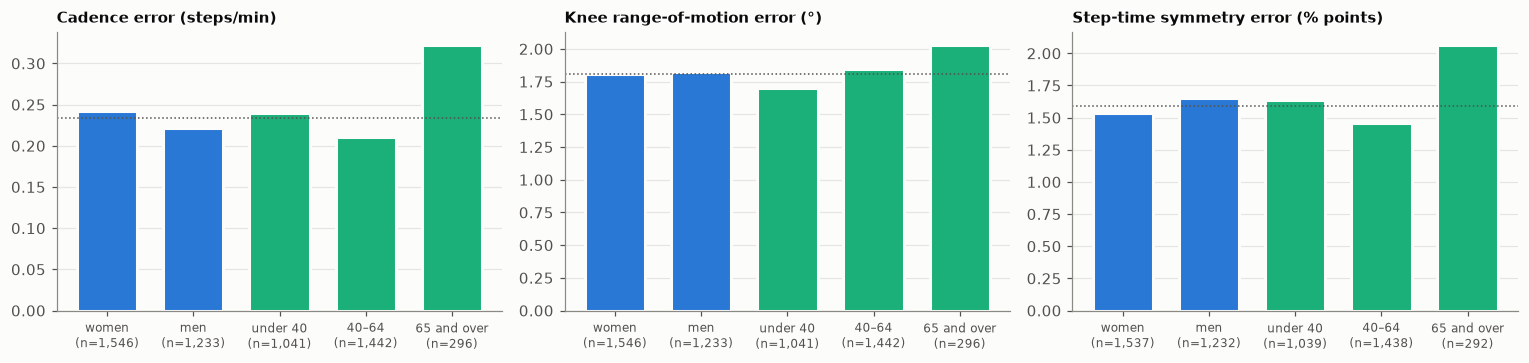

In [9]:
P = pd.read_parquet(EVAL / "test" / "predictions.parquet").query("level == 0.02 and method == 'bigru_v4+derived'")
P = P.merge(T[["trial", "sex", "age"]], on="trial", how="left")
P["group_sex"] = P.sex.map({"F": "women", "Female": "women", "M": "men", "Male": "men"})
P["group_age"] = pd.cut(P.age, [0, 40, 65, 120], right=False, labels=["under 40", "40–64", "65 and over"])
show = [("cadence", "Cadence error (steps/min)"), ("knee_rom", "Knee range-of-motion error (°)"),
        ("SI_step_time", "Step-time symmetry error (% points)")]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for a, (k, title) in zip(axs, show):
    err = (P[f"pred_{k}"] - P[f"true_{k}"]).abs()
    groups = [(g, err[P.group_sex == g]) for g in ("women", "men")] + [(str(g), err[P.group_age == g]) for g in P.group_age.cat.categories]
    vals = [e.mean() for _, e in groups]
    a.bar(range(5), vals, color=[SERIES[0]] * 2 + [SERIES[2]] * 3, edgecolor=SURFACE, linewidth=2, width=0.7)
    a.axhline(err.mean(), color=INK2, ls=":", lw=1)
    a.set_xticks(range(5), [f"{g}\n(n={e.notna().sum():,})" for g, e in groups], fontsize=8)
    a.set_title(title, fontsize=10); a.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

Errors are similar accross genders. They are somewhat larger for people aged 65 and over, whose walking is slower and more variable and who are represented less in the training data. A professional clinical tool would need more older and patient data before it is trusted for them.

## 7. Does it report a limp at its true size?

A common failure of models trained mostly on healthy people is to somewhat ignore asymmetry: they report everyone as nearly symmetric. Each point is a held-out recording. the true step-time symmetry (from the
gait lab) vs. what the model reported from damaged video input. Perfect answers should lie on the diagonal. The slope is representative on the model's representation of real asymmetry. 1.0 means perfect representation.

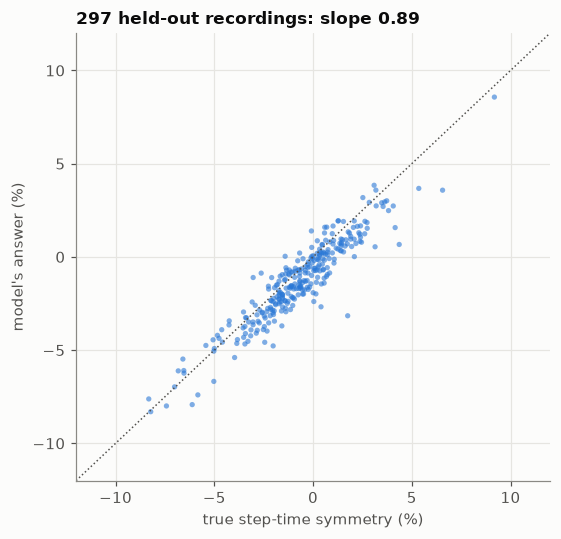

Average error 0.82 % points, versus 1.77 for guessing the average. About 89 % of a real asymmetry is reported.


In [10]:
P = pd.read_parquet(EVAL / "test_trial" / "predictions.parquet")
P = P[(P.level == 0.02) & (P.method == "bigru_v4+derived") & (P.dataset == "ferber")].dropna(subset=["true_SI_step_time", "pred_SI_step_time"])
tv, pv = P.true_SI_step_time.to_numpy(), P.pred_SI_step_time.to_numpy()
slope = np.polyfit(tv, pv, 1)[0]
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(tv, pv, s=12, color=MODEL, alpha=0.6, edgecolor="none")
lim = [-12, 12]
ax.plot(lim, lim, color=INK2, lw=1, ls=":"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("true step-time symmetry (%)"); ax.set_ylabel("model's answer (%)")
ax.set_title(f"{len(P)} held-out recordings: slope {slope:.2f}")
fig.tight_layout(); plt.show()
print(f"Average error {np.abs(pv - tv).mean():.2f} % points, versus {np.abs(tv - tv.mean()).mean():.2f} for guessing the average. "
      f"About {100 * slope:.0f} % of a real asymmetry is reported.")

The model reports step-time asymmetry close to its true size (earlier versions of the model let only
about half of it through so fixing this was a very celebrated part of the project). Asymmetry of stance and swing time is
still under-reported.**

## 8. Tests on real video

The entries above used gait lab data with simulated video errors. The Kuopio dataset includes data points closer to what the deployment case is. (42 people filmed by a real video camera at the same time as the gait lab and force plates recorded them). The
model has never seen this data before. Real video turned out to be messier than our simulation (approximately equal to sigma = 4 in the gradio demo) (the errors are also larger at the feet and tend to persist across frames rather than flicker), so this is a
tough test.

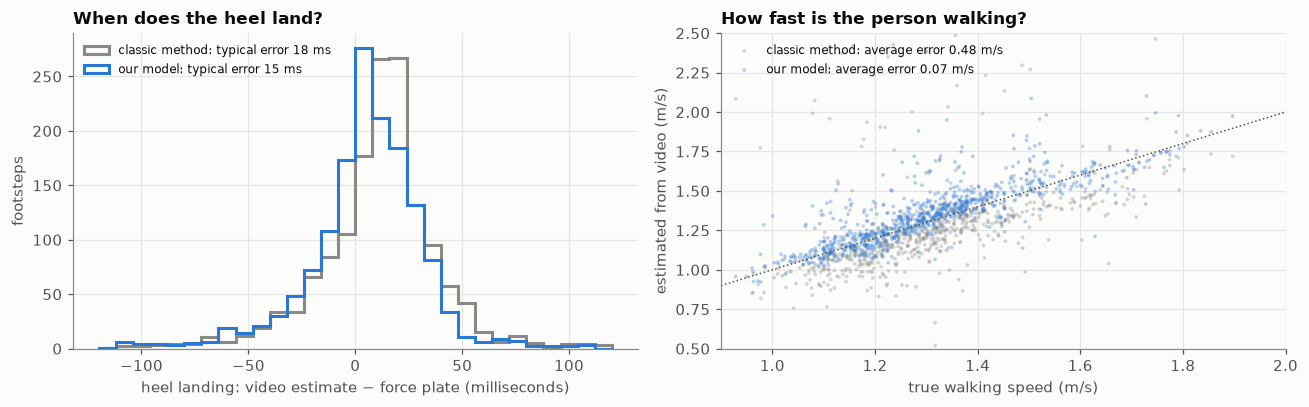

,classic method (°),our model (°)
"error in range of motion, real video",,
ankle,13.5,3.8
hip,5.7,4.1
knee,8.3,5.7


In [11]:
E = pd.read_parquet(KUO / "events.parquet")
SP = pd.read_csv(KUO / "speed.csv")
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8))
for meth, col, lab in (("classic", CLASSIC, "classic method"), ("model", MODEL, "our model")):
    d = E[(E.condition == "real") & (E.method == meth) & (E.event == "HS")]
    err = np.concatenate([np.array(v, float) for v in d.err_ms])
    a.hist(err, bins=np.arange(-120, 121, 8), histtype="step", lw=2, color=col,
           label=f"{lab}: typical error {np.median(np.abs(err)):.0f} ms")
    s = SP[(SP.condition == "real") & (SP.method == meth)]
    b.scatter(s.true_ms, s.pred_ms, s=6, alpha=0.35, color=col, edgecolor="none",
              label=f"{lab}: average error {np.abs(s.pred_ms - s.true_ms).mean():.2f} m/s")
a.set_xlabel("heel landing: video estimate − force plate (milliseconds)"); a.set_ylabel("footsteps")
a.set_title("When does the heel land?"); a.legend(fontsize=8)
b.plot([0.9, 2], [0.9, 2], color=INK2, lw=1, ls=":"); b.set_xlim(0.9, 2); b.set_ylim(0.5, 2.5)
b.set_xlabel("true walking speed (m/s)"); b.set_ylabel("estimated from video (m/s)")
b.set_title("How fast is the person walking?"); b.legend(fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()
A = pd.read_csv(KUO / "angles_summary.csv").query("condition == 'real'").groupby(["method", "joint"]).exc_mae.mean().unstack(0)
A.columns = ["classic method (°)", "our model (°)"]
A.index.name = "error in range of motion, real video"
A.round(1)

On real video (from a new camera, lab and person) the model finds heel landings to within about one video frame, estimates walking speed to within about 0.08m/s (the classic method is six times
worse for reference), and measures joint range of motion more accurately than the classic method, especially at the ankle.

## 9. Conclusion and Evaluation Points

* **Real video is harder than our training simulation.** Accuracy on real video is roughly what we measured
  for twice the simulated noise.
* **Some left/right comparisons are not reliable from video yet.** Knee-motion symmetry works on real video but hip and ankle motion symmetry were only somewhat better than guessing. The ankle is small in the picture and the foot keypoints are the least precise. This is the primary reason for the error on the ankle, so some of it can be attributed to the pose model used, which isn't the primary focus of this project.
* **Stance and swing-time asymmetry are under-reported** (about 60 % gets through). This is somewhat due to the gait lab reference being uncertain for toe-off events.
* **Side view only.** The model only takes in side views for simplicity. This excludes sideways sway of the hips or knees.
* **Healthy and orthopaedic walkers only.** No stroke, Parkinson's or amputee walkers were in the data, so the tool must be tested on such patients before being reliable enough.

**Conclusion:** from an ordinary side perspective video the tool measures walking rhythm, speed and knee motion
well, and asymmetries reasonably well, even on people it has never seen. It is a promising way to track a
patient's progress between visits, but not diagnose a patient.

*This project is a prototype and is not medical advice.*